In [47]:
import pandas as pd

customers = pd.read_csv(
    "data/olist_customers_dataset.csv"
)

print("Rows and columns:", customers.shape)
print("Memory usage:")
print(customers.memory_usage(deep=True).sum() / (1024 ** 2), "MB")

Rows and columns: (99441, 5)
Memory usage:
26.58640480041504 MB


In [3]:
customers.head(10)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
5,879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC
6,fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,4534,sao paulo,SP
7,5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,timoteo,MG
8,5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR
9,4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,belo horizonte,MG


In [48]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [25]:
customers.shape

(99441, 5)

In [6]:
customers.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [7]:
customers.duplicated().sum()

np.int64(0)

In [50]:
top_states = (
    customers["customer_state"]
    .value_counts()
    .head(10)
)

print(top_states)

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: count, dtype: int64


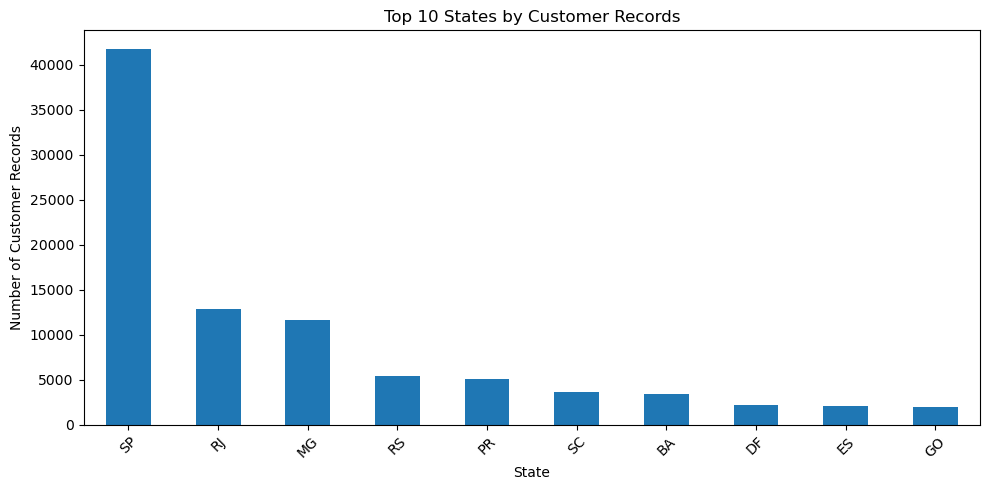

In [51]:
import matplotlib.pyplot as plt

top_states.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 States by Customer Records")
plt.xlabel("State")
plt.ylabel("Number of Customer Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [52]:
customers.duplicated().sum()

np.int64(0)

In [53]:
customers["customer_id"].nunique()

99441

In [12]:
customers["customer_unique_id"].nunique()

96096

### Initial Customer Data Exploration

- Dataset size: 99,441 rows and 5 columns.
- Missing values: None found in the five columns.
- State with the most customer records: SP (São Paulo).
- Next steps: Check duplicate records, count unique customers, and investigate the distribution of customers across cities.

**Initial observation:** The customer records are geographically concentrated in São Paulo. Further analysis with the orders dataset will help us understand how this distribution relates to actual purchases.

In [54]:
import pandas as pd

orders = pd.read_csv("data/olist_orders_dataset.csv")
order_items = pd.read_csv("data/olist_order_items_dataset.csv")

print("Orders shape:", orders.shape)
print("Order items shape:", order_items.shape)

Orders shape: (99441, 8)
Order items shape: (112650, 7)


In [7]:
display(orders.head())
display(order_items.head())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,02-10-2017 10:56,02-10-2017 11:07,04-10-2017 19:55,10-10-2017 21:25,18-10-2017 00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,24-07-2018 20:41,26-07-2018 03:24,26-07-2018 14:31,07-08-2018 15:27,13-08-2018 00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,08-08-2018 08:38,08-08-2018 08:55,08-08-2018 13:50,17-08-2018 18:06,04-09-2018 00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,18-11-2017 19:28,18-11-2017 19:45,22-11-2017 13:39,02-12-2017 00:28,15-12-2017 00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,13-02-2018 21:18,13-02-2018 22:20,14-02-2018 19:46,16-02-2018 18:17,26-02-2018 00:00


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [46]:
print("Orders information:")
orders.info()
print(orders.isnull().sum())

print("\nOrder items information:")
order_items.info()
print(order_items.isnull().sum())

Orders information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivere

In [45]:
order_analysis = pd.merge(
    orders,
    order_items,
    on="order_id",
    how="inner"
)

print("Combined dataset shape:", order_analysis.shape)

display(order_analysis.head())

Combined dataset shape: (112650, 14)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,02-10-2017 10:56,02-10-2017 11:07,04-10-2017 19:55,10-10-2017 21:25,18-10-2017 00:00,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,24-07-2018 20:41,26-07-2018 03:24,26-07-2018 14:31,07-08-2018 15:27,13-08-2018 00:00,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,08-08-2018 08:38,08-08-2018 08:55,08-08-2018 13:50,17-08-2018 18:06,04-09-2018 00:00,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,18-11-2017 19:28,18-11-2017 19:45,22-11-2017 13:39,02-12-2017 00:28,15-12-2017 00:00,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,13-02-2018 21:18,13-02-2018 22:20,14-02-2018 19:46,16-02-2018 18:17,26-02-2018 00:00,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [26]:
# Total sales revenue from delivered orders
# Select delivered orders
delivered_orders = order_analysis[
    order_analysis["order_status"] == "delivered"
].copy()

# Calculate total revenue
total_revenue = delivered_orders["price"].sum()

# Display results
print("Total sales revenue: R$", round(total_revenue, 2))
print("Total delivered orders:", delivered_orders["order_id"].nunique())
print("Total items sold:", len(delivered_orders))

Total sales revenue: R$ 13221498.11
Total delivered orders: 96478
Total items sold: 110197


In [29]:
# Convert timestamps using day-month-year format
delivered_orders["order_purchase_timestamp"] = pd.to_datetime(
    delivered_orders["order_purchase_timestamp"],
    format="%d-%m-%Y %H:%M",
    errors="coerce"
)

# Extract month
delivered_orders["month"] = (
    delivered_orders["order_purchase_timestamp"].dt.to_period("M")
)

# Calculate monthly revenue
monthly_sales = delivered_orders.groupby("month")["price"].sum()

print(monthly_sales)

month
2016-09       134.97
2016-10     40325.11
2016-12        10.90
2017-01    111798.36
2017-02    234223.40
2017-03    359198.85
2017-04    340669.68
2017-05    489338.25
2017-06    421923.37
2017-07    481604.52
2017-08    554699.70
2017-09    607399.67
2017-10    648247.65
2017-11    987765.37
2017-12    726033.19
2018-01    924645.00
2018-02    826437.13
2018-03    953356.25
2018-04    973534.09
2018-05    977544.69
2018-06    856077.86
2018-07    867953.46
2018-08    838576.64
Freq: M, Name: price, dtype: float64


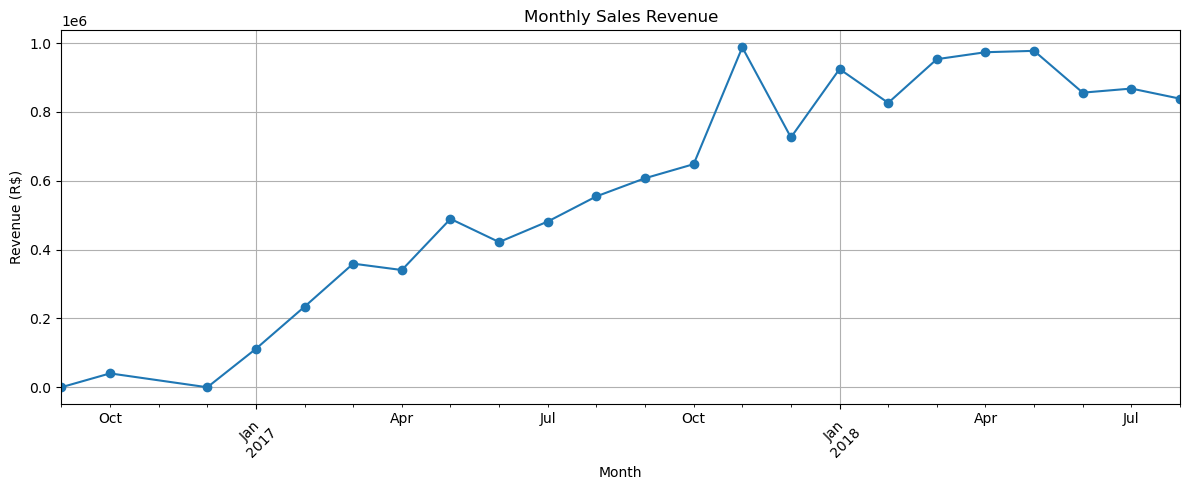

In [30]:
import matplotlib.pyplot as plt

monthly_sales.plot(kind="line", marker="o", figsize=(12, 5))

plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [31]:
best_month = monthly_sales.idxmax()
best_revenue = monthly_sales.max()

worst_month = monthly_sales.idxmin()
worst_revenue = monthly_sales.min()

print("Best sales month:", best_month)
print("Highest revenue: R$", round(best_revenue, 2))

print("\nLowest sales month:", worst_month)
print("Lowest revenue: R$", round(worst_revenue, 2))

Best sales month: 2017-11
Highest revenue: R$ 987765.37

Lowest sales month: 2016-12
Lowest revenue: R$ 10.9


In [32]:
# Total item revenue for each delivered order
order_revenue = delivered_orders.groupby("order_id")["price"].sum()

# Average revenue per order
aov = order_revenue.mean()

print("Average Order Value: R$", round(aov, 2))

Average Order Value: R$ 137.04


In [33]:
# Add customer state to each order item
sales_with_state = delivered_orders.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

# Calculate revenue by state
state_sales = (
    sales_with_state.groupby("customer_state")["price"]
    .sum()
    .sort_values(ascending=False)
)

print(state_sales.head(10))

customer_state
SP    5067633.16
RJ    1759651.13
MG    1552481.83
RS     728897.47
PR     666063.51
SC     507012.13
BA     493584.14
DF     296498.41
GO     282836.70
ES     268643.45
Name: price, dtype: float64


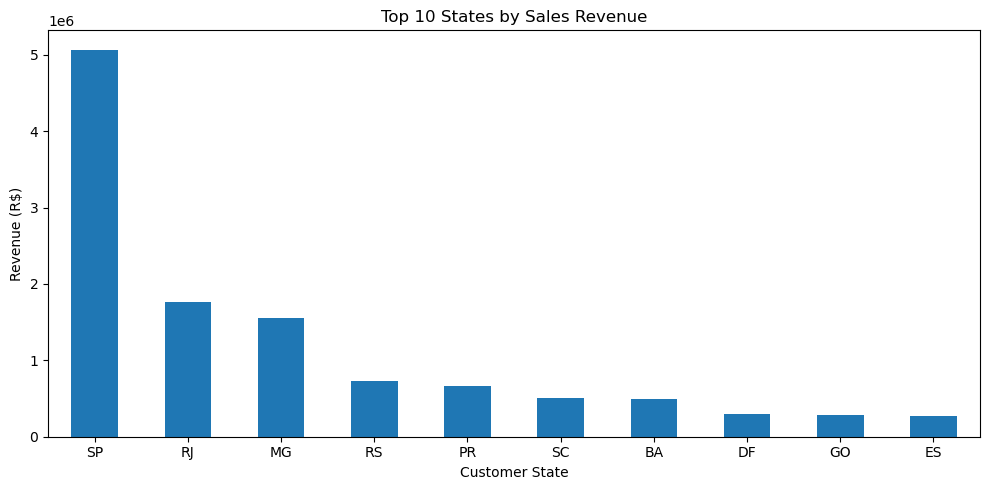

In [44]:
import matplotlib.pyplot as plt

top_10_states = state_sales.head(10)

top_10_states.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 States by Sales Revenue")
plt.xlabel("Customer State")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [34]:
state_percentage = (
    state_sales / delivered_orders["price"].sum()
) * 100

print(state_percentage.head(10).round(2))

customer_state
SP    38.33
RJ    13.31
MG    11.74
RS     5.51
PR     5.04
SC     3.83
BA     3.73
DF     2.24
GO     2.14
ES     2.03
Name: price, dtype: float64


In [35]:
# Count distinct orders for each customer
customer_orders = (
    delivered_orders.groupby("customer_id")["order_id"]
    .nunique()
)

# Count customers who placed more than one delivered order
repeat_customers = (customer_orders > 1).sum()

total_customers = customer_orders.nunique()

print("Customers with repeat orders:", repeat_customers)
print("Total customers with delivered orders:", len(customer_orders))

repeat_rate = repeat_customers / len(customer_orders) * 100

print("Repeat customer rate:", round(repeat_rate, 2), "%")

Customers with repeat orders: 0
Total customers with delivered orders: 96478
Repeat customer rate: 0.0 %


In [36]:
# Add unique customer IDs to delivered order items
delivered_with_customers = delivered_orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

# Count distinct delivered orders per unique customer
customer_orders = (
    delivered_with_customers.groupby("customer_unique_id")["order_id"]
    .nunique()
)

# Calculate repeat customers
repeat_customers = (customer_orders > 1).sum()
total_customers = customer_orders.index.nunique()

repeat_rate = repeat_customers / total_customers * 100

print("Repeat customers:", repeat_customers)
print("Total unique customers:", total_customers)
print("Repeat customer rate:", round(repeat_rate, 2), "%")

Repeat customers: 2801
Total unique customers: 93358
Repeat customer rate: 3.0 %


In [37]:
# Calculate revenue by product
product_revenue = (
    delivered_orders.groupby("product_id")["price"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 products by revenue:")
print(product_revenue.head(10))

Top 10 products by revenue:
product_id
bb50f2e236e5eea0100680137654686c    63560.00
6cdd53843498f92890544667809f1595    53652.30
d6160fb7873f184099d9bc95e30376af    45949.35
d1c427060a0f73f6b889a5c7c61f2ac4    45620.56
99a4788cb24856965c36a24e339b6058    42049.66
3dd2a17168ec895c781a9191c1e95ad7    40782.80
25c38557cf793876c5abdd5931f922db    38907.32
5f504b3a1c75b73d6151be81eb05bdc9    37733.90
53b36df67ebb7c41585e8d54d6772e08    37454.63
aca2eb7d00ea1a7b8ebd4e68314663af    37104.30
Name: price, dtype: float64


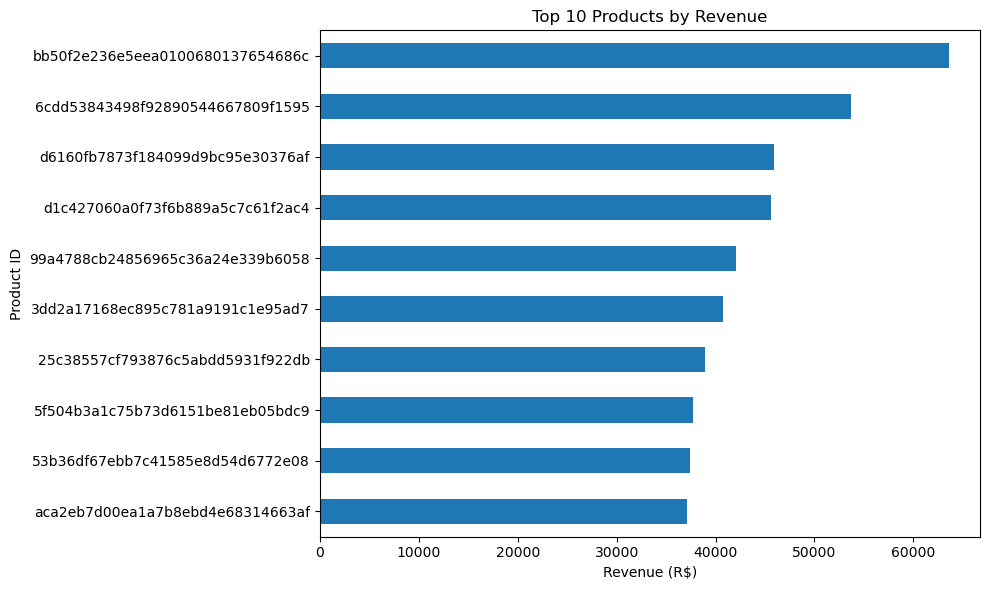

In [38]:
top_products = product_revenue.head(10).sort_values()

top_products.plot(kind="barh", figsize=(10, 6))

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("Product ID")
plt.tight_layout()
plt.show()

In [39]:
products = pd.read_csv("data/olist_products_dataset.csv")

print("Products shape:", products.shape)
display(products.head())

Products shape: (32951, 9)


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [40]:
product_sales = delivered_orders.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

category_revenue = (
    product_sales.groupby("product_category_name")["price"]
    .sum()
    .sort_values(ascending=False)
)

print(category_revenue.head(10))

product_category_name
beleza_saude              1233131.72
relogios_presentes        1166176.98
cama_mesa_banho           1023434.76
esporte_lazer              954852.55
informatica_acessorios     888724.61
moveis_decoracao           711927.69
utilidades_domesticas      615628.69
cool_stuff                 610204.10
automotivo                 578966.65
brinquedos                 471286.48
Name: price, dtype: float64


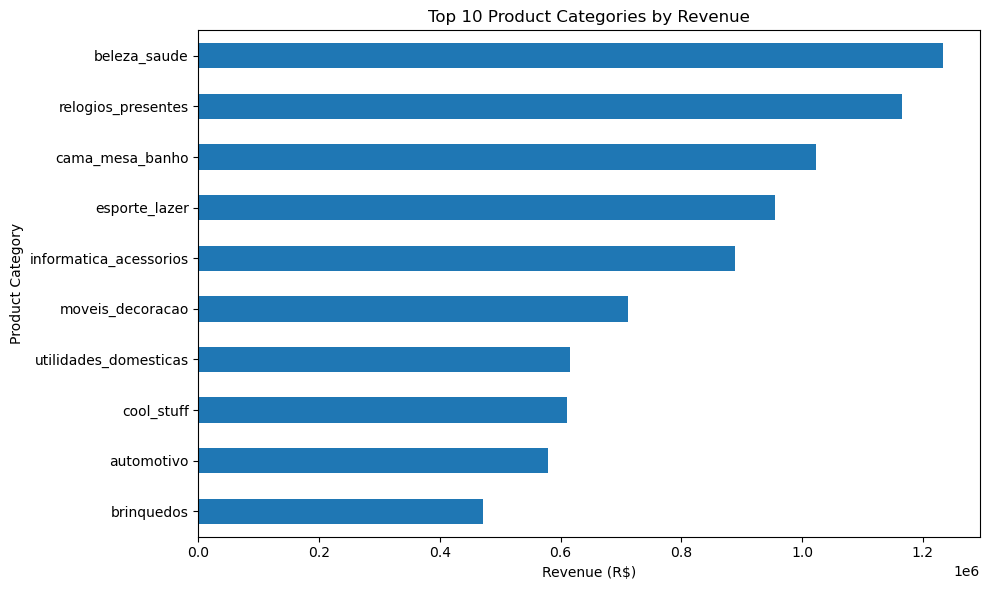

In [41]:
top_categories = category_revenue.head(10).sort_values()

top_categories.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [42]:
print(
    "Missing product categories:",
    product_sales["product_category_name"].isnull().sum()
)

print(
    "Total delivered order-item rows:",
    len(product_sales)
)

Missing product categories: 1537
Total delivered order-item rows: 110197


In [43]:
# Create a cleaned copy
product_sales_clean = product_sales.copy()

# Fill missing categories
product_sales_clean["product_category_name"] = (
    product_sales_clean["product_category_name"]
    .fillna("Unknown")
)

# Verify the result
print(
    "Missing categories after cleaning:",
    product_sales_clean["product_category_name"].isnull().sum()
)

print(
    product_sales_clean["product_category_name"]
    .value_counts()
    .head(10)
)

Missing categories after cleaning: 0
product_category_name
cama_mesa_banho           10953
beleza_saude               9465
esporte_lazer              8431
moveis_decoracao           8160
informatica_acessorios     7644
utilidades_domesticas      6795
relogios_presentes         5859
telefonia                  4430
ferramentas_jardim         4268
automotivo                 4140
Name: count, dtype: int64


In [23]:
product_sales_clean.to_csv(
    "data/cleaned_order_analysis.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
